# Intro

In [1]:
ALPHA=0.05

## Modules

### Standard

In [2]:
import os, pickle, platform, sys, json
import numpy as np
import copy
import torch

In [3]:
from collections import defaultdict

In [4]:
import dcms
from dcms.models import DCMModel, DECMModel, qDECMModel, DWCMModel

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.size'] = 10
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.size'] = 10
plt.rcParams['ytick.major.width'] = 2

plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14

plt.rcParams['xtick.minor.size'] = 5
plt.rcParams['xtick.minor.width'] = 1
plt.rcParams['ytick.minor.size'] = 5
plt.rcParams['ytick.minor.width'] = 1
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.ticker import ScalarFormatter

In [6]:
from scipy.stats import spearmanr

In [7]:
from tqdm.notebook import tqdm, trange

In [8]:
import datetime as dt

In [9]:
from bowtie import edges2bowtie

In [10]:
from tabulate import tabulate

In [11]:
from sklearn.metrics import jaccard_score as js
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import precision_score as precision
from sklearn.metrics import recall_score as recall
from sklearn.metrics import balanced_accuracy_score as b_accuracy

### Home made

In [12]:
if platform.system() == 'Darwin':
    print('Air!')
    HOME = '/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/bowtie2/'
elif platform.system() == 'Linux':
    print('Stella!')
    HOME = '/home/sarawalk/bowtie2_py39/bowtie2/'
else:
    raise RuntimeError(f"Unsupported OS: {platform.system()}")

sys.path.insert(0, HOME)

Air!


In [13]:
from bowtie_plot_functions import plot_bowtie_blocks, plot_bowtie_fluxes, _add_colorbar
from bowtie_plot_functions import _fdr as fdr

## Folders

In [14]:
DATA_FOLDER=HOME+'dati_elezioni/'
TEST_FOLDER=HOME+'tests/'
GUARINO_FOLDER=HOME+'guarino_files/'
BIPARTITE_FOLDER=HOME+'BiDCM/'
PLOT_FOLDER=HOME+'plots/'

In [15]:
if platform.system() == 'Darwin':
    os.system("afplay ta-da.mp3")
    PVALUE_FOLDER = '/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/benchmark_19/results_final/pvalues/'
elif platform.system() == 'Linux':
    
    PVALUE_FOLDER = '/home/sarawalk/bowtie2_py39/bowtie2/benchmark_19/results_final/pvalues/'
else:
    raise RuntimeError(f"Unsupported OS: {platform.system()}")


## Names for $\LaTeX$
#### Names as in the draft

In [16]:
def parse_dico_names(filepath):
    with open(filepath, 'r') as f:
        lines = [line.strip().split() for line in f]
        # such a command creates a list
        # in which each element is a list of tokens of a line in the file
        # remarkably, there is an empty element
        # before each dataset name
        

    result = {}
    current_key = None

    for tokens in lines:
        if not tokens:
            current_key = None
        elif current_key is None:
            # prima riga non vuota del gruppo: nome del dataset
            current_key = tokens[0]
            result[current_key] = {}
        else:
            # riga tipo ['5:', 'journalists', '&', 'Media']
            idx = int(tokens[0].rstrip(':'))
            label = ' '.join(tokens[1:])
            result[current_key][idx] = label

    return result

In [17]:
cacca=parse_dico_names(GUARINO_FOLDER+'all_dico_labels.txt')

In [18]:
name_changer={'c0': 'Crisis - Centrists', 'c1': 'Crisis - Centre-right', 'c2': 'Crisis - M5S', 'c3': 'Crisis - PD', 'c4': 'Crisis - Media', 'e0': 'Elections - Centre-right', 'e1': 'Elections - Centre-left', 'e2': 'Elections - M5S', 'e3': 'Elections - Centrists', 'e4': 'Elections - Others', 'e5': 'Elections - Media', 'e6': 'Elections - Others 2', 'p0': 'President -  Centrists', 'p1': 'President -  PD', 'p2': 'President -  M5S', 'p3': 'President -  Media', 'p4': 'President -  Right', 'p5': 'President -  Others', 'p6': 'President -  FI'}

#### Proper scientific notation for the Latex table

In [19]:
def sci_latex(x, dec=2, bold=False):
    # da Claude
    mant, exp = f'{x:.{dec}e}'.split('e')
    if bold:
        return f'$\\mathbf{{{mant}\\times 10^{{{int(exp)}}}}}$'
    return f'${mant}\\times 10^{{{int(exp)}}}$'


## Functions

In [20]:
def p_value_right_tail(count_sample, obs, l_sample):
    """
    Compute the empirical p-value based on the count sample and observed value.

    Parameters:
    count_sample (array-like): The sample of counts from the null distribution.
    obs (float): The observed value to compare against the null distribution.
    l_sample (int): The number of samples in count_sample.

    Returns:
    float: The empirical p-value.
    """
    if len(count_sample) == 0:
        return 1.0
    else:
        return (np.sum(np.array(count_sample) >= obs) + 1) / (l_sample + 1)

In [21]:
def p_value_two_tailed(count_sample, obs, l_sample):
    """
    Compute the empirical two-tailed p-value based on the count sample and observed value.

    Parameters:
    count_sample (array-like): The sample of counts from the null distribution.
    obs (float): The observed value to compare against the null distribution.
    l_sample (int): The number of samples in count_sample.

    Returns:
    float: The empirical two-tailed p-value, 2*min(p_left, p_right), capped at 1.
    """
    if len(count_sample) == 0:
        return 1.0
    count_sample = np.asarray(count_sample)
    p_right = (np.sum(count_sample >= obs) + 1) / (l_sample + 1)
    p_left = (np.sum(count_sample <= obs) + 1) / (l_sample + 1)
    return min(1.0, 2 * min(p_left, p_right))


# Blocks

## Get p-values

In [22]:
models=['dwcm', 'qdecm', 'decm']

In [23]:
n_samples=5000

In [24]:
datasets=[]
block_p_values = defaultdict(dict)
block_mean = defaultdict(dict)
block_std = defaultdict(dict)
block_obs = defaultdict(dict)
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'block' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
    
        dataset=f"{name}{dico}"
        if dataset=='e6':
            # for this network, the bowtie is degenerate, so we skip it
            continue
        if dataset not in datasets:
            datasets.append(dataset)
        block_p_values[dataset][model] = {}
        block_mean[dataset][model] = {}
        block_std[dataset][model] = {}

        with open(subfolder+file, 'rb') as f:
            _aux = pickle.load(f)
        for key in _aux.keys():
            # acutally, the test should be two-tailed for blocks
            p_value = p_value_two_tailed(_aux[key]['count_sample'], _aux[key]['obs'], n_samples)
            block_p_values[dataset][model][key] = p_value
            block_mean[dataset][model][key] = np.mean(_aux[key]['count_sample'])
            block_std[dataset][model][key] = np.std(_aux[key]['count_sample'])
            block_obs[dataset][key] = _aux[key]['obs']

### All together now

In [25]:
blocks=list(block_p_values['c0']['dwcm'].keys())
blocks.sort()
n_blocks = len(blocks)

In [26]:
blocks

['IN', 'INTENDRILS', 'OTHERS', 'OUT', 'OUTTENDRILS', 'SCC', 'TUBES']

In [27]:
dwcm_p_values=[block_p_values[dataset]['dwcm'][key] for dataset in datasets for key in blocks]
decm_p_values=[block_p_values[dataset]['decm'][key] for dataset in datasets for key in blocks]
qdecm_p_values=[block_p_values[dataset]['qdecm'][key] for dataset in datasets for key in blocks]

In [1]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(dwcm_p_values, decm_p_values, color='blue', alpha=0.7, label='DWCM vs DECM')
axs[1].scatter(qdecm_p_values, decm_p_values, color='red', alpha=0.7, label='qDECM vs DECM')
for i in range(2):
    axs[i].plot([-2, 2], [-2, 2], '--', lw=2, color='gray')
    axs[i].set_xlim(-0.05, 1.05)
    axs[i].set_ylim(-0.05, 1.05)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[0].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
plt.show()

NameError: name 'plt' is not defined

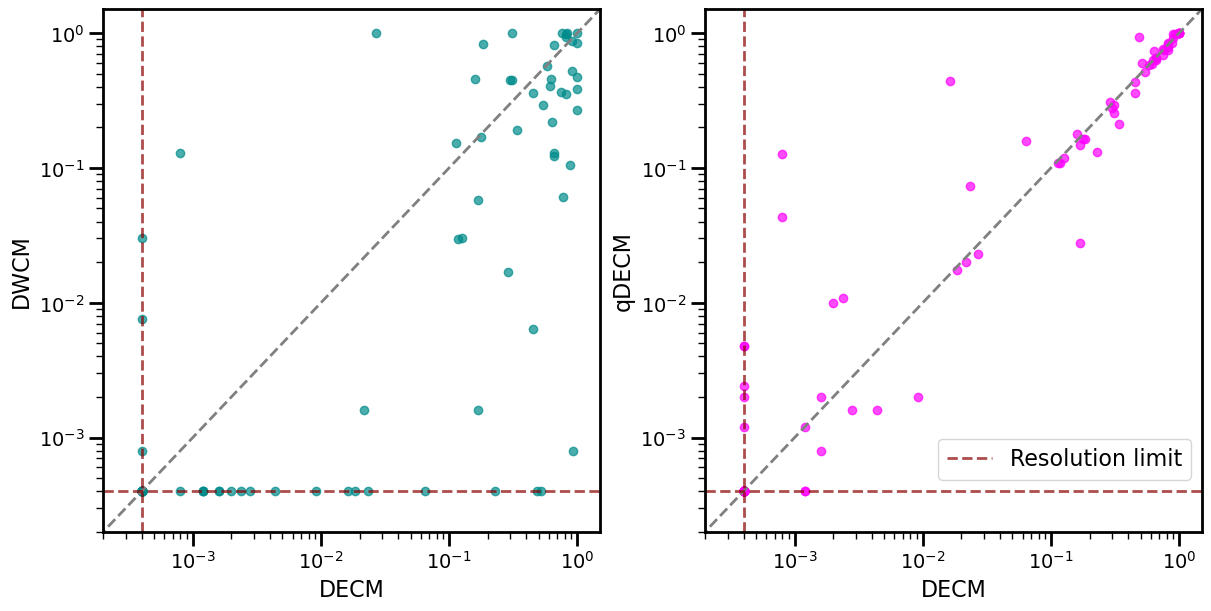

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6),layout="constrained")
axs[0].scatter(decm_p_values,dwcm_p_values, color='darkcyan', alpha=0.7)
axs[1].scatter(decm_p_values,qdecm_p_values, color='magenta', alpha=0.7)
for i in range(2):
    axs[i].plot([1e-5, 2], [1e-5, 2], '--', lw=2, color='gray')
    axs[i].hlines(2/(n_samples+1), 1/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7, label=r'Resolution limit')
    axs[i].vlines(2/(n_samples+1), 1/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7)
        
    axs[i].set_xlim(2e-4, 1.5)
    axs[i].set_ylim(2e-4, 1.5)
    axs[i].set_xscale('log')
    axs[i].set_yscale('log')
axs[1].legend(fontsize=16, loc=(.47,.1))
axs[0].set_xlabel('DECM', fontsize=16)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
plt.savefig(PLOT_FOLDER+f"p_value_block_comparison.png", dpi=300)
plt.show()

In [30]:
1/(n_samples+1)

0.0001999600079984003

## Debug: why excluding e6?

In [90]:
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'block' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
        
        dataset=f"{name}{dico}"
        if dataset!='e6':
            continue
        else:
            with open(subfolder+file, 'rb') as f:
                _aux = pickle.load(f)

In [91]:
_aux['SCC']['obs']

1

In [92]:
for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'block' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
        
        dataset=f"{name}{dico}"
        if dataset!='p6':
            continue
        else:
            with open(subfolder+file, 'rb') as f:
                _aux = pickle.load(f)

In [93]:
_aux['SCC']['obs']

7

## Validated ones

In [31]:
val_p_blocks=defaultdict(list)
for key in block_p_values.keys():
    if key=='e6':
        continue
    for i, model in enumerate(models):
        p_values=np.ones(len(blocks))
        for i_b, block in enumerate(blocks):
            if block in block_p_values[key][model].keys():
                p_values[i_b]=block_p_values[key][model][block]
        alpha_fdr=fdr(p_values, ALPHA)
        val_p=p_values<=alpha_fdr
        val_p_blocks[key].append(val_p.astype(int))

In [32]:
val_blocks=[0, 0, 0]
for key in val_p_blocks.keys():
    for i, model in enumerate(models):
        val_blocks[i]+=np.sum(val_p_blocks[key][i])

In [33]:
models, val_blocks

(['dwcm', 'qdecm', 'decm'], [87, 79, 82])

qDECM is the one validating the least (and it makes sense, as it is the one with the best likelihood).

### F1
F1 = harmonic mean of precision ($\dfrac{TP}{TP+FP}$) and recall ($\dfrac{TP}{P}$). If $|P|=0$, it fails.

In [97]:
f1_scores_dwcm_decm = []
f1_scores_qdecm_decm = []
for key in val_p_blocks.keys():
    if np.sum(val_p_blocks[key][0])>0:
        f1_scores_dwcm_decm.append(f1(val_p_blocks[key][2], val_p_blocks[key][0]))
        f1_scores_qdecm_decm.append(f1(val_p_blocks[key][2], val_p_blocks[key][1]))

In [98]:
np.mean(f1_scores_dwcm_decm), np.mean(f1_scores_qdecm_decm)

(0.9333653274829746, 0.9737190913661502)

In [99]:
for key in val_p_blocks.keys():
    if key!='c0':
        dwcm_all=np.concatenate((dwcm_all, val_p_blocks[key][0]))
        qdecm_all=np.concatenate((qdecm_all, val_p_blocks[key][1]))
        decm_all=np.concatenate((decm_all, val_p_blocks[key][2]))
    else:
        dwcm_all=val_p_blocks[key][0]
        qdecm_all=val_p_blocks[key][1]
        decm_all=val_p_blocks[key][2]

In [100]:
f1(decm_all, dwcm_all), f1(decm_all, qdecm_all)

(0.9467455621301775, 0.968944099378882)

### Accuracy
$\dfrac{TP+TN}{P+N}$

In [101]:
acc_scores_dwcm_decm = []
acc_scores_qdecm_decm = []
for key in val_p_blocks.keys():
    acc_scores_dwcm_decm.append(accuracy(val_p_blocks[key][2], val_p_blocks[key][0]))
    acc_scores_qdecm_decm.append(accuracy(val_p_blocks[key][2], val_p_blocks[key][1]))

In [102]:
np.mean(acc_scores_dwcm_decm), np.mean(acc_scores_qdecm_decm)

(0.9285714285714286, 0.9603174603174602)

In [103]:
accuracy(dwcm_all, decm_all), accuracy(qdecm_all, decm_all)

(0.9285714285714286, 0.9603174603174603)

### Balanced Accuracy
$\dfrac{1}{2}(\dfrac{TP}{P}+\dfrac{TN}{N})$

In [104]:
def b_acc(y_true, y_pred):
    """
    Compute the balanced accuracy score.

    Parameters:
    y_true (array-like): True labels.
    y_pred (array-like): Predicted labels.

    Returns:
    float: Balanced accuracy score. If the input arrays are fully one-class, returns 1.0 if the predictions are correct, otherwise returns the proportion of correct predictions.
    
    """
    if len(np.unique(y_true)) == 1:
        # If y_true is fully one-class, check if predictions are correct
        return 1.0 if np.all(y_true == y_pred) else np.sum(y_true == y_pred)/len(y_pred)
    return b_accuracy(y_true, y_pred)

In [105]:
b_acc_scores_dwcm_decm = []
b_acc_scores_qdecm_decm = []
for key in val_p_blocks.keys():
    if np.sum(val_p_blocks[key][0])>0:
        b_acc_scores_dwcm_decm.append(b_acc(val_p_blocks[key][2], val_p_blocks[key][0]))
        b_acc_scores_qdecm_decm.append(b_acc(val_p_blocks[key][2], val_p_blocks[key][1]))
    else:
        print(f"Skipping {key} because DWCM has no significant blocks.")
        sys.stdout.flush()

Skipping p6 because DWCM has no significant blocks.


In [106]:
np.mean(b_acc_scores_dwcm_decm), np.mean(b_acc_scores_qdecm_decm)

(0.8382352941176471, 0.946498599439776)

In [107]:
b_acc(dwcm_all, decm_all), b_acc(qdecm_all, decm_all)

(0.9341290893015031, 0.9511176945865877)

### Recall
$\dfrac{TP}{P}$

In [108]:
recall(decm_all, dwcm_all), recall(decm_all, qdecm_all)

(0.975609756097561, 0.9512195121951219)

Over the set of all validated entries, both DWCM and qDECM have the same capability of finding the entries validated by DECM.

### Specificity
$\dfrac{TN}{N}$=2 BA-Recall

In [109]:
2*b_accuracy(dwcm_all, decm_all)-recall(decm_all, dwcm_all)

0.8926484225054452

In [110]:
2*b_accuracy(decm_all, qdecm_all)-recall(decm_all, qdecm_all)

0.9772727272727273

That is the most important result among all: qDECM is the strictest one among all, but its non-validated entries are those non validated by DECM as well. Therefore, the difference is in a couple of ones already validated by DECM.

# Flows

## Get p-values

In [22]:
models=['dwcm', 'qdecm', 'decm']
n_samples=5000

In [24]:
# not all flows are allowed, so we define the set of allowed flows
allowed_flows={'IN->IN',
 'IN->INTENDRILS',
 'IN->OUT',
 'IN->SCC',
 'IN->TUBES',
 'INTENDRILS->INTENDRILS',
 'OTHERS->INTENDRILS',
 'OTHERS->OTHERS',
 'OUT->OUT',
 'OUTTENDRILS->INTENDRILS',
 'OUTTENDRILS->OTHERS',
 'OUTTENDRILS->OUT',
 'OUTTENDRILS->OUTTENDRILS',
 'OUTTENDRILS->TUBES',
 'SCC->OUT',
 'SCC->SCC',
 'TUBES->INTENDRILS',
 'TUBES->OUT',
 'TUBES->TUBES'}
len(allowed_flows)

19

In [26]:
flow_p_values = defaultdict(dict)
datasets=[]

for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'flux' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
    
        dataset=f"{name}{dico}"
        if dataset=='e6':
            # for this network, the bowtie is degenerate, so we skip it
            continue
        if dataset not in datasets:
            datasets.append(dataset)
                        
        flow_p_values[dataset][model] = {}


        with open(subfolder+file, 'rb') as f:
            _aux = pickle.load(f)
        for key in _aux.keys():
            if key in allowed_flows:
                p_value = p_value_right_tail(_aux[key]['count_sample'], _aux[key]['obs'], 5000)
                flow_p_values[dataset][model][key] = p_value
            else:
                assert _aux[key]['obs']==0, f'Bug in bow-tie: flow {key} in dataset {dataset}={_aux[key]["obs"]}'

## All together now

In [27]:
n_flows = len(allowed_flows)

In [28]:
dwcm_p_values=[]
decm_p_values=[]
qdecm_p_values=[]
bad_p_values=[]
for dataset in datasets:
    if dataset=='e6':
        # for this network, the bowtie is degenerate, so we skip it
        continue
            
    for key in allowed_flows:
        if all([key in flow_p_values[dataset][model].keys() for model in models]):
            dwcm_p_values.append(flow_p_values[dataset]['dwcm'][key])
            decm_p_values.append(flow_p_values[dataset]['decm'][key])
            qdecm_p_values.append(flow_p_values[dataset]['qdecm'][key])
        elif all([key not in flow_p_values[dataset][model].keys() for model in models]):
            continue
        else:
            who_is_in=[model for model in models if key in flow_p_values[dataset][model].keys()]
            bad_p_values.append((dataset, key, who_is_in))

## Plots

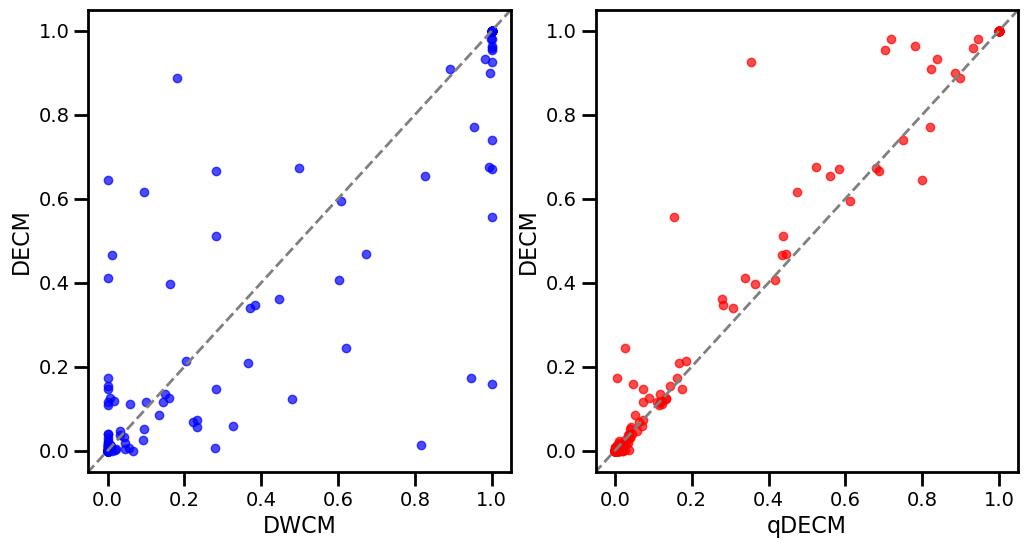

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(dwcm_p_values, decm_p_values, color='blue', alpha=0.7, label='DWCM vs DECM')
axs[1].scatter(qdecm_p_values, decm_p_values, color='red', alpha=0.7, label='qDECM vs DECM')
for i in range(2):
    axs[i].plot([-2, 2], [-2, 2], '--', lw=2, color='gray')
    axs[i].set_xlim(-0.05, 1.05)
    axs[i].set_ylim(-0.05, 1.05)
axs[0].set_xlabel('DWCM', fontsize=16)
axs[0].set_ylabel('DECM', fontsize=16)
axs[1].set_xlabel('qDECM', fontsize=16)
axs[1].set_ylabel('DECM', fontsize=16)
plt.show()

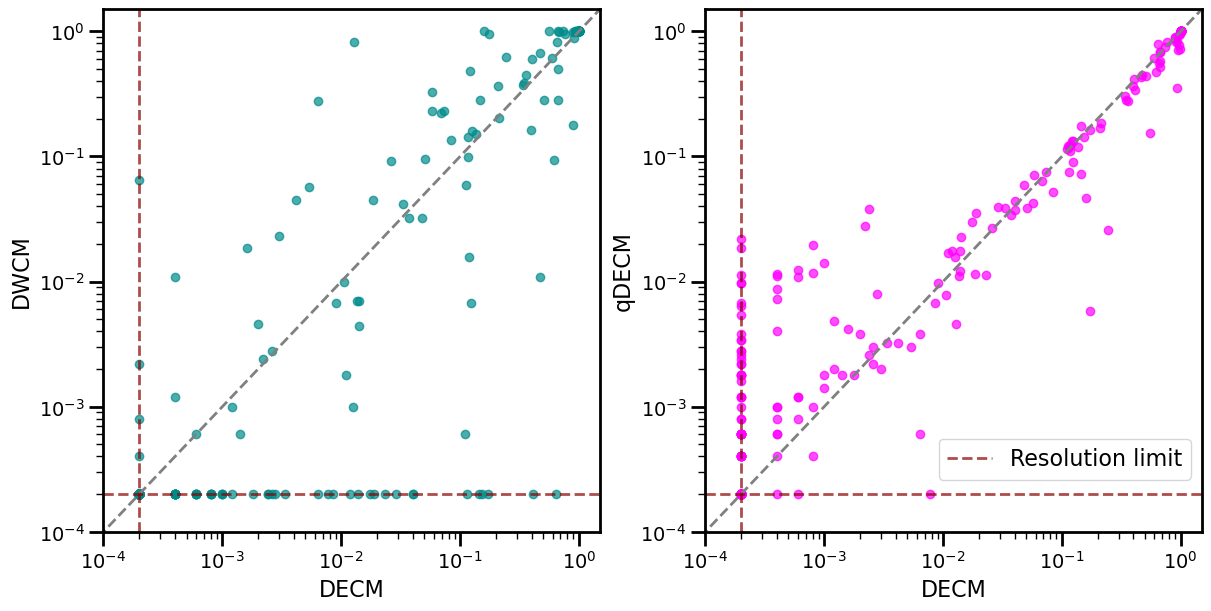

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6),layout="constrained")
axs[0].scatter(decm_p_values,dwcm_p_values, color='darkcyan', alpha=0.7)
axs[1].scatter(decm_p_values,qdecm_p_values, color='magenta', alpha=0.7)
for i in range(2):
    axs[i].plot([1e-5, 2], [1e-5, 2], '--', lw=2, color='gray')
    axs[i].hlines(1/(n_samples+1), 1/2/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7, label=r'Resolution limit')
    axs[i].vlines(1/(n_samples+1), 1/2/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
                
    axs[i].set_xlim(1e-4, 1.5)
    axs[i].set_ylim(1e-4, 1.5)
    axs[i].set_xscale('log')
    axs[i].set_yscale('log')
    #axs[i].legend(fontsize=16)
axs[1].legend(fontsize=16, loc=(.47,.1))
axs[0].set_xlabel('DECM', fontsize=16)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
plt.savefig(PLOT_FOLDER+f"p_value_flow_comparison.png", dpi=300)
plt.show()

## Validated ones

In [32]:
val_p_flows=defaultdict(list)
for key in flow_p_values.keys():
    if key=='e6':
        continue
    for i, model in enumerate(models):
        # unobserved fluxes are not in the dictionary and their p-value is always 1
        p_values=np.ones(len(allowed_flows))
        for i_f, flow in enumerate(allowed_flows):
            if flow in flow_p_values[key][model].keys():
                p_values[i_f]=flow_p_values[key][model][flow]
        alpha_fdr=fdr(p_values, ALPHA)
        val_p=p_values<=alpha_fdr
        val_p_flows[key].append(val_p.astype(int))

In [33]:
val_flows=[0, 0, 0]
for key in val_p_flows.keys():
    for i, model in enumerate(models):
        val_flows[i]+=np.sum(val_p_flows[key][i])

In [34]:
models, val_flows

(['dwcm', 'qdecm', 'decm'], [206, 202, 198])

qDECM is the one validating the least (and it makes sense, as it is the one with the best likelihood).

### F1
F1 = harmonic mean of precision ($\dfrac{TP}{TP+FP}$) and recall ($\dfrac{TP}{P}$). If $|P|=0$, it fails.

In [35]:
f1_scores_dwcm_decm = []
f1_scores_qdecm_decm = []
for key in val_p_flows.keys():
    if np.sum(val_p_flows[key][0])>0:
        f1_scores_dwcm_decm.append(f1(val_p_flows[key][2], val_p_flows[key][0]))
        f1_scores_qdecm_decm.append(f1(val_p_flows[key][2], val_p_flows[key][1]))

In [36]:
np.mean(f1_scores_dwcm_decm), np.mean(f1_scores_qdecm_decm)

(0.9267263555006241, 0.9921769501549503)

In [37]:
for key in val_p_flows.keys():
    if key!='c0':
        dwcm_all=np.concatenate((dwcm_all, val_p_flows[key][0]))
        qdecm_all=np.concatenate((qdecm_all, val_p_flows[key][1]))
        decm_all=np.concatenate((decm_all, val_p_flows[key][2]))
    else:
        dwcm_all=val_p_flows[key][0]
        qdecm_all=val_p_flows[key][1]
        decm_all=val_p_flows[key][2]

In [38]:
f1(decm_all, dwcm_all), f1(decm_all, qdecm_all)

(0.9455445544554455, 0.99)

### Accuracy
$\dfrac{TP+TN}{P+N}$

In [39]:
acc_scores_dwcm_decm = []
acc_scores_qdecm_decm = []
for key in val_p_flows.keys():
    acc_scores_dwcm_decm.append(accuracy(val_p_flows[key][2], val_p_flows[key][0]))
    acc_scores_qdecm_decm.append(accuracy(val_p_flows[key][2], val_p_flows[key][1]))

In [40]:
np.mean(acc_scores_dwcm_decm), np.mean(acc_scores_qdecm_decm)

(0.935672514619883, 0.9883040935672516)

In [41]:
accuracy(dwcm_all, decm_all), accuracy(qdecm_all, decm_all)

(0.935672514619883, 0.9883040935672515)

### Balanced Accuracy
$\dfrac{1}{2}(\dfrac{TP}{P}+\dfrac{TN}{N})$

In [42]:
b_acc_scores_dwcm_decm = []
b_acc_scores_qdecm_decm = []
for key in val_p_flows.keys():
    if np.sum(val_p_flows[key][0])>0:
        b_acc_scores_dwcm_decm.append(b_accuracy(val_p_flows[key][2], val_p_flows[key][0]))
        b_acc_scores_qdecm_decm.append(b_accuracy(val_p_flows[key][2], val_p_flows[key][1]))

In [43]:
np.mean(b_acc_scores_dwcm_decm), np.mean(b_acc_scores_qdecm_decm)

(0.9452913099971924, 0.9782407407407407)

In [44]:
b_accuracy(dwcm_all, decm_all), b_accuracy(qdecm_all, decm_all)

(0.9378569388920617, 0.9900990099009901)

### Recall
$\dfrac{TP}{P}$

In [45]:
recall(decm_all, dwcm_all), recall(decm_all, qdecm_all)

(0.9646464646464646, 1.0)

Over the set of all validated entries, both DWCM and qDECM have the same capability of finding the entries validated by DECM.

### Specificity
$\dfrac{TN}{N}$=2 BA-Recall

In [46]:
2*b_accuracy(dwcm_all, decm_all)-recall(decm_all, dwcm_all)

0.9110674131376587

In [47]:
2*b_accuracy(decm_all, qdecm_all)-recall(decm_all, qdecm_all)

0.9722222222222223

That is the most important result among all: qDECM is the strictest one among all, but its non-validated entries are nearly all those non validated by DECM as well. Therefore, the difference is mainly in a couple of ones already validated by DECM.

# Blocks: e0 and e2 examples

In [72]:
name_changer

{'c0': 'Crisis - Centrists',
 'c1': 'Crisis - Centre-right',
 'c2': 'Crisis - M5S',
 'c3': 'Crisis - PD',
 'c4': 'Crisis - Media',
 'e0': 'Elections - Centre-right',
 'e1': 'Elections - Centre-left',
 'e2': 'Elections - M5S',
 'e3': 'Elections - Centrists',
 'e4': 'Elections - Others',
 'e5': 'Elections - Media',
 'e6': 'Elections - Others 2',
 'p0': 'President -  Centrists',
 'p1': 'President -  PD',
 'p2': 'President -  M5S',
 'p3': 'President -  Media',
 'p4': 'President -  Right',
 'p5': 'President -  Others',
 'p6': 'President -  FI'}

## e0

In [114]:
models

['dwcm', 'qdecm', 'decm']

In [115]:
blocks_guarino=['SCC', 'IN', 'OUT', 'TUBES', 'INTENDRILS', 'OUTTENDRILS', 'OTHERS']

In [116]:
guarino_dict={'SCC':'LSCC', 'INTENDRILS':'IN-TEND', 'OUTTENDRILS':'OUT-TEND'}

In [117]:
dataset='e0'

In [118]:
guarino_style_table_e0=[]
for block in blocks_guarino:
    aux_vec=[]
    if block in guarino_dict:
        aux_vec.append(guarino_dict[block])
    else:
        aux_vec.append(block)
    _obs=block_obs[dataset][block]
    aux_vec.append(f'{_obs:,}'.replace(',', ' '))
    for model in models:
        _mean=block_mean[dataset][model][block]
        aux_vec.append(f'{_mean:,.1f}'.replace(',', ' '))
        _std=block_std[dataset][model][block]
        _z=(_obs-_mean)/_std
        if _z>0:
            aux_vec.append(f'$+{_z:,.1f}$'.replace(',', ' '))
        else:
            aux_vec.append(f'${_z:,.1f}$'.replace(',', ' '))
        aux_vec.append(sci_latex(block_p_values[dataset][model][block],dec=1))
        _fdr_th=fdr(np.array([block_p_values[dataset][model][block] for block in blocks_guarino]), ALPHA)
        if block_p_values[dataset][model][block]<=_fdr_th:
            aux_vec.append(f'$\\checkmark$')
        else:
            aux_vec.append(f'$-$')

    guarino_style_table_e0.append(aux_vec)

In [119]:
headers=['','','Expected', f'$z$', f'$q$', 'sig.' ,'Expected', f'$z$', f'$q$', 'sig.' , 'Expected', f'$z$', f'$q$', 'sig.']

In [120]:
print(tabulate(guarino_style_table_e0, headers=headers, tablefmt="latex_raw"))

\begin{tabular}{llllllllllllll}
\hline
          &        & Expected   & $z$      & $q$                 & sig.         & Expected   & $z$      & $q$                 & sig.         & Expected   & $z$      & $q$                 & sig.         \\
\hline
 LSCC     & 5 882  & 5 203.7    & $+15.6$  & $4.0\times 10^{-4}$ & $\checkmark$ & 5 203.5    & $+13.9$  & $4.0\times 10^{-4}$ & $\checkmark$ & 5 132.0    & $+15.5$  & $4.0\times 10^{-4}$ & $\checkmark$ \\
 IN       & 3 694  & 3 203.8    & $+13.0$  & $4.0\times 10^{-4}$ & $\checkmark$ & 3 428.4    & $+6.1$   & $4.0\times 10^{-4}$ & $\checkmark$ & 3 352.5    & $+8.0$   & $4.0\times 10^{-4}$ & $\checkmark$ \\
 OUT      & 27 004 & 28 106.3   & $-8.2$   & $4.0\times 10^{-4}$ & $\checkmark$ & 27 095.9   & $-0.4$   & $6.0\times 10^{-1}$ & $-$          & 27 107.5   & $-0.5$   & $5.2\times 10^{-1}$ & $-$          \\
 TUBES    & 137    & 54.4       & $+10.9$  & $4.0\times 10^{-4}$ & $\checkmark$ & 54.6       & $+9.9$   & $4.0\times 10^{-4}$ & $\chec

## e3

In [102]:
models

['dwcm', 'qdecm', 'decm']

In [103]:
blocks_guarino=['SCC', 'IN', 'OUT', 'TUBES', 'INTENDRILS', 'OUTTENDRILS', 'OTHERS']

In [104]:
guarino_dict={'SCC':'LSCC', 'INTENDRILS':'IN-TEND', 'OUTTENDRILS':'OUT-TEND'}

In [105]:
dataset='e3'

In [106]:
guarino_style_table_e3=[]
for block in blocks_guarino:
    aux_vec=[]
    if block in guarino_dict:
        aux_vec.append(guarino_dict[block])
    else:
        aux_vec.append(block)
    _obs=block_obs[dataset][block]
    aux_vec.append(f'{_obs:,}'.replace(',', ' '))
    for model in models:
        _mean=block_mean[dataset][model][block]
        aux_vec.append(f'{_mean:,.1f}'.replace(',', ' '))
        _std=block_std[dataset][model][block]
        _z=(_obs-_mean)/_std
        if _z>0:
            aux_vec.append(f'$+{_z:,.1f}$'.replace(',', ' '))
        else:
            aux_vec.append(f'${_z:,.1f}$'.replace(',', ' '))
        aux_vec.append(sci_latex(block_p_values[dataset][model][block],dec=1))
        _fdr_th=fdr(np.array([block_p_values[dataset][model][block] for block in blocks_guarino]), ALPHA)
        if block_p_values[dataset][model][block]<=_fdr_th:
            aux_vec.append(f'$\\checkmark$')
        else:
            aux_vec.append(f'$-$')

    guarino_style_table_e3.append(aux_vec)

In [107]:
headers=['','','Expected', f'$z$', f'$q$', 'sig.' ,'Expected', f'$z$', f'$q$', 'sig.' , 'Expected', f'$z$', f'$q$', 'sig.']

In [108]:
print(tabulate(guarino_style_table_e3, headers=headers, tablefmt="latex_raw"))

\begin{tabular}{llllllllllllll}
\hline
          &        & Expected   & $z$     & $q$                 & sig.         & Expected   & $z$     & $q$                 & sig.         & Expected   & $z$     & $q$                 & sig.         \\
\hline
 LSCC     & 3 672  & 3 325.0    & $+11.5$ & $4.0\times 10^{-4}$ & $\checkmark$ & 3 492.8    & $+5.9$  & $4.0\times 10^{-4}$ & $\checkmark$ & 3 452.3    & $+7.4$  & $4.0\times 10^{-4}$ & $\checkmark$ \\
 IN       & 1 800  & 1 683.9    & $+4.4$  & $4.0\times 10^{-4}$ & $\checkmark$ & 1 918.4    & $-4.3$  & $4.0\times 10^{-4}$ & $\checkmark$ & 1 890.9    & $-3.2$  & $1.2\times 10^{-3}$ & $\checkmark$ \\
 OUT      & 18 135 & 16 837.2   & $+16.8$ & $4.0\times 10^{-4}$ & $\checkmark$ & 16 555.5   & $+14.9$ & $4.0\times 10^{-4}$ & $\checkmark$ & 16 469.2   & $+16.2$ & $4.0\times 10^{-4}$ & $\checkmark$ \\
 TUBES    & 48     & 11.8       & $+10.3$ & $4.0\times 10^{-4}$ & $\checkmark$ & 6.2        & $+15.9$ & $4.0\times 10^{-4}$ & $\checkmark$ & 7.7  

# Two steps? One step? 

In [ ]:
two_step_flow=['IN->SCC', 'SCC->OUT', 'SCC->SCC']
one_step_flow=['IN->OUT']

In [59]:
two_step_flow_n=np.array([np.where(np.array(list(allowed_flows))==flow)[0][0] for flow in two_step_flow])
one_step_flow_n=np.array([np.where(np.array(list(allowed_flows))==flow)[0][0] for flow in one_step_flow])

In [60]:
for dataset in datasets:
    if dataset=='e6':
        continue
    for i_m, model in enumerate(models):
        
        output='none'
        
        two_step = np.all(val_p_flows[dataset][i_m][two_step_flow_n])
        one_step=np.all(val_p_flows[dataset][i_m][one_step_flow_n])
        
        if two_step and one_step:
            output='one+two-step'
        elif two_step:
            output='two-step'
        elif one_step:
            output='one-step'
        if output!='none':
            print(f"{name_changer[dataset]} - {model}: {output}")

Crisis - PD - dwcm: two-step
Elections - M5S - dwcm: one-step
Elections - Media - dwcm: two-step
Elections - Media - qdecm: two-step
Elections - Media - decm: two-step
President -  PD - dwcm: one+two-step
President -  PD - qdecm: one+two-step
President -  PD - decm: one+two-step
President -  Media - dwcm: two-step
President -  Media - qdecm: two-step
President -  Media - decm: two-step


Non c'è un cazzo.

# Flows, two tails

## Get p-values

In [22]:
models=['dwcm', 'qdecm', 'decm']
n_samples=5000

In [23]:
# not all flows are allowed, so we define the set of allowed flows
allowed_flows={'IN->IN',
 'IN->INTENDRILS',
 'IN->OUT',
 'IN->SCC',
 'IN->TUBES',
 'INTENDRILS->INTENDRILS',
 'OTHERS->INTENDRILS',
 'OTHERS->OTHERS',
 'OUT->OUT',
 'OUTTENDRILS->INTENDRILS',
 'OUTTENDRILS->OTHERS',
 'OUTTENDRILS->OUT',
 'OUTTENDRILS->OUTTENDRILS',
 'OUTTENDRILS->TUBES',
 'SCC->OUT',
 'SCC->SCC',
 'TUBES->INTENDRILS',
 'TUBES->OUT',
 'TUBES->TUBES'}
len(allowed_flows)

19

In [26]:
flow_p_values = defaultdict(dict)
flow_tail = defaultdict(dict)
datasets=[]

for model in models:
    subfolder=PVALUE_FOLDER+f"{model}/"
    files=[f for f in os.listdir(subfolder) if 'flux' in f]
    files.sort()
    for file in files:
        # proper name
        if 'elections' in file.lower():
            name='e'
        elif 'crisi' in file.lower():
            name='c'
        elif 'quirinale' in file.lower():
            name='p'
        else:
            print(f"Unknown dataset in solution {file}. Skipping.")
            continue
        
        try:
            i_dico=file.index('dico')
            dico=file[i_dico+4]
        except ValueError:
            print(f"No 'dico' found in solution {file}. Skipping.")
            continue
    
        dataset=f"{name}{dico}"
        if dataset=='e6':
            # for this network, the bowtie is degenerate, so we skip it
            continue
        if dataset not in datasets:
            datasets.append(dataset)
                        
        flow_p_values[dataset][model] = {}
        flow_tail[dataset][model] = {}


        with open(subfolder+file, 'rb') as f:
            _aux = pickle.load(f)
        for key in _aux.keys():
            if key in allowed_flows:
                p_value = p_value_two_tailed(_aux[key]['count_sample'], _aux[key]['obs'], 5000)
                flow_p_values[dataset][model][key] = p_value
                if np.median(_aux[key]['count_sample']) < _aux[key]['obs']:
                    flow_tail[dataset][model][key] = 'right'
                else:
                    flow_tail[dataset][model][key] = 'left'
            else:
                assert _aux[key]['obs']==0, f'Bug in bow-tie: flow {key} in dataset {dataset}={_aux[key]["obs"]}'

## All together now

In [27]:
n_flows = len(allowed_flows)

In [28]:
dwcm_p_values=[]
decm_p_values=[]
qdecm_p_values=[]
bad_p_values=[]
for dataset in datasets:
    if dataset=='e6':
        # for this network, the bowtie is degenerate, so we skip it
        continue
            
    for key in allowed_flows:
        if all([key in flow_p_values[dataset][model].keys() for model in models]):
            dwcm_p_values.append(flow_p_values[dataset]['dwcm'][key])
            decm_p_values.append(flow_p_values[dataset]['decm'][key])
            qdecm_p_values.append(flow_p_values[dataset]['qdecm'][key])
        elif all([key not in flow_p_values[dataset][model].keys() for model in models]):
            continue
        else:
            who_is_in=[model for model in models if key in flow_p_values[dataset][model].keys()]
            bad_p_values.append((dataset, key, who_is_in))

## Plots

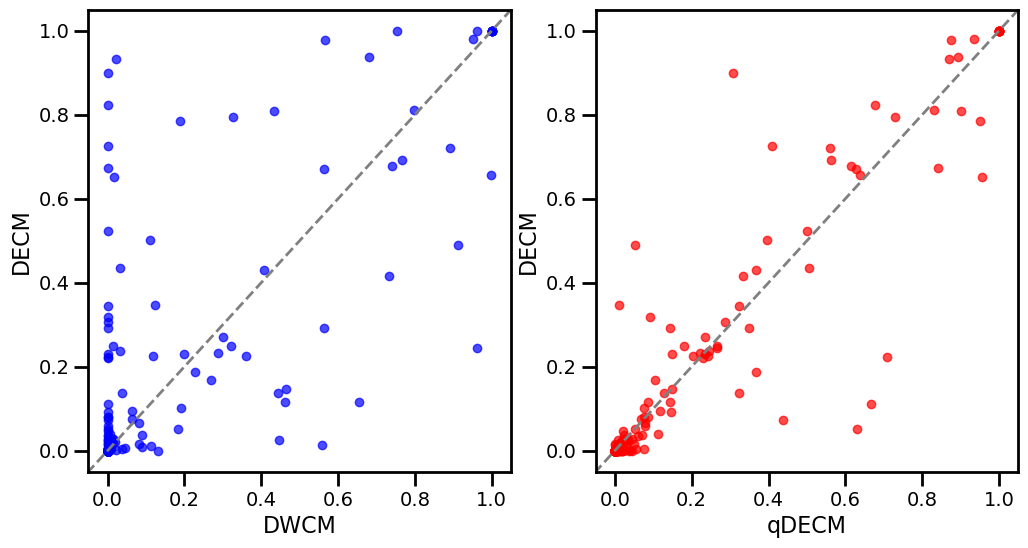

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(dwcm_p_values, decm_p_values, color='blue', alpha=0.7, label='DWCM vs DECM')
axs[1].scatter(qdecm_p_values, decm_p_values, color='red', alpha=0.7, label='qDECM vs DECM')
for i in range(2):
    axs[i].plot([-2, 2], [-2, 2], '--', lw=2, color='gray')
    axs[i].set_xlim(-0.05, 1.05)
    axs[i].set_ylim(-0.05, 1.05)
axs[0].set_xlabel('DWCM', fontsize=16)
axs[0].set_ylabel('DECM', fontsize=16)
axs[1].set_xlabel('qDECM', fontsize=16)
axs[1].set_ylabel('DECM', fontsize=16)
plt.show()

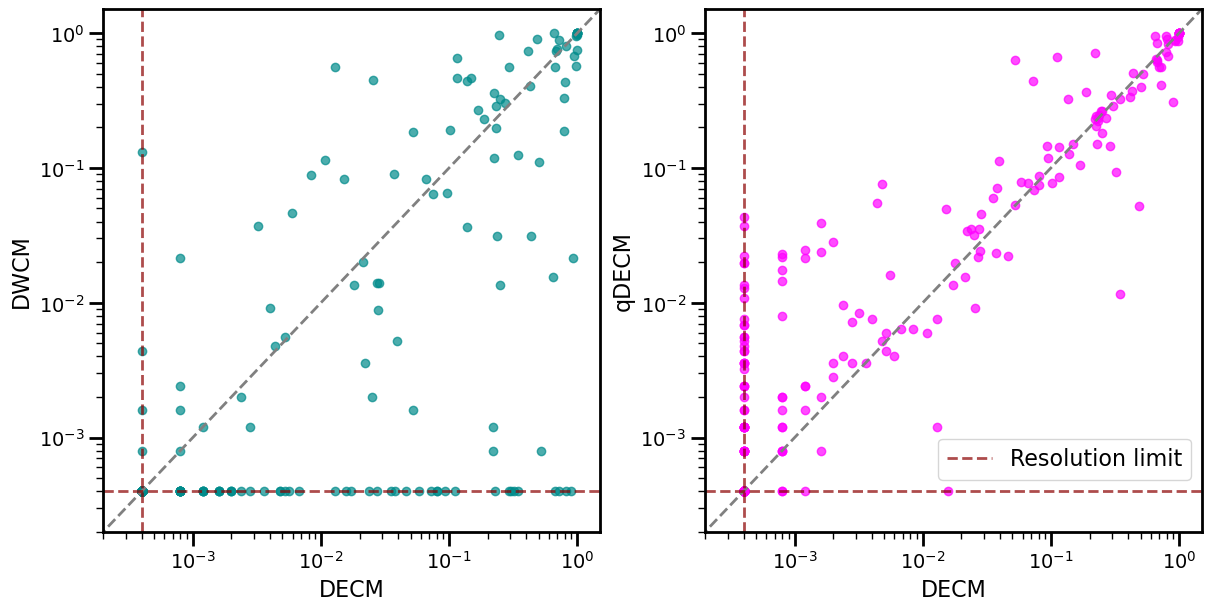

In [32]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6),layout="constrained")
axs[0].scatter(decm_p_values,dwcm_p_values, color='darkcyan', alpha=0.7)
axs[1].scatter(decm_p_values,qdecm_p_values, color='magenta', alpha=0.7)
for i in range(2):
    axs[i].plot([1e-5, 2], [1e-5, 2], '--', lw=2, color='gray')
    axs[i].hlines(2/(n_samples+1), 1/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7, label=r'Resolution limit')
    axs[i].vlines(2/(n_samples+1), 1/(n_samples+1), 1.5, colors='darkred', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(2*ALPHA/n_blocks, 1e-5, 1.5, colors='red', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(3*ALPHA/n_blocks, 1e-5, 1.5, colors='darkorange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].hlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
    #axs[i].vlines(4*ALPHA/n_blocks, 1e-5, 1.5, colors='orange', linestyles='--', linewidth=2, alpha=0.7)
                
    axs[i].set_xlim(2e-4, 1.5)
    axs[i].set_ylim(2e-4, 1.5)
    axs[i].set_xscale('log')
    axs[i].set_yscale('log')
    #axs[i].legend(fontsize=16)
axs[1].legend(fontsize=16, loc=(.47,.1))
axs[0].set_xlabel('DECM', fontsize=16)
axs[0].set_ylabel('DWCM', fontsize=16)
axs[1].set_xlabel('DECM', fontsize=16)
axs[1].set_ylabel('qDECM', fontsize=16)
#plt.savefig(PLOT_FOLDER+f"p_value_flow_comparison.png", dpi=300)
plt.show()

## Validated ones

In [77]:
val_p_flows=defaultdict(list)
for key in flow_p_values.keys():
    if key=='e6':
        continue
    for i, model in enumerate(models):
        # unobserved fluxes are not in the dictionary and their p-value is always 1
        p_values=np.ones(len(allowed_flows))
        for i_f, flow in enumerate(allowed_flows):
            if flow in flow_p_values[key][model].keys():
                p_values[i_f]=flow_p_values[key][model][flow]
            else:
                p_values[i_f]=2/(n_samples+1)
        alpha_fdr=fdr(p_values, ALPHA)
        val_p=p_values<=alpha_fdr
        val_p_flows[key].append(val_p.astype(int))

In [78]:
val_flows=[0, 0, 0]
for key in val_p_flows.keys():
    for i, model in enumerate(models):
        val_flows[i]+=np.sum(val_p_flows[key][i])

In [79]:
models, val_flows

(['dwcm', 'qdecm', 'decm'], [290, 265, 271])

qDECM is the one validating the least (and it makes sense, as it is the one with the best likelihood).

### F1
F1 = harmonic mean of precision ($\dfrac{TP}{TP+FP}$) and recall ($\dfrac{TP}{P}$). If $|P|=0$, it fails.

In [80]:
f1_scores_dwcm_decm = []
f1_scores_qdecm_decm = []
for key in val_p_flows.keys():
    if np.sum(val_p_flows[key][0])>0:
        f1_scores_dwcm_decm.append(f1(val_p_flows[key][2], val_p_flows[key][0]))
        f1_scores_qdecm_decm.append(f1(val_p_flows[key][2], val_p_flows[key][1]))

In [81]:
np.mean(f1_scores_dwcm_decm), np.mean(f1_scores_qdecm_decm)

(0.931850783260438, 0.9855648153052677)

In [82]:
for key in val_p_flows.keys():
    if key!='c0':
        dwcm_all=np.concatenate((dwcm_all, val_p_flows[key][0]))
        qdecm_all=np.concatenate((qdecm_all, val_p_flows[key][1]))
        decm_all=np.concatenate((decm_all, val_p_flows[key][2]))
    else:
        dwcm_all=val_p_flows[key][0]
        qdecm_all=val_p_flows[key][1]
        decm_all=val_p_flows[key][2]

In [83]:
f1(decm_all, dwcm_all), f1(decm_all, qdecm_all)

(0.9411764705882353, 0.9850746268656716)

### Accuracy
$\dfrac{TP+TN}{P+N}$

In [84]:
acc_scores_dwcm_decm = []
acc_scores_qdecm_decm = []
for key in val_p_flows.keys():
    acc_scores_dwcm_decm.append(accuracy(val_p_flows[key][2], val_p_flows[key][0]))
    acc_scores_qdecm_decm.append(accuracy(val_p_flows[key][2], val_p_flows[key][1]))

In [85]:
np.mean(acc_scores_dwcm_decm), np.mean(acc_scores_qdecm_decm)

(0.9035087719298244, 0.9766081871345028)

In [86]:
accuracy(dwcm_all, decm_all), accuracy(qdecm_all, decm_all)

(0.9035087719298246, 0.9766081871345029)

### Balanced Accuracy
$\dfrac{1}{2}(\dfrac{TP}{P}+\dfrac{TN}{N})$

In [87]:
b_acc_scores_dwcm_decm = []
b_acc_scores_qdecm_decm = []
for key in val_p_flows.keys():
    if np.sum(val_p_flows[key][0])>0:
        b_acc_scores_dwcm_decm.append(b_accuracy(val_p_flows[key][2], val_p_flows[key][0]))
        b_acc_scores_qdecm_decm.append(b_accuracy(val_p_flows[key][2], val_p_flows[key][1]))

/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/fabio/Documents/Lavoro/PythonFiles/bowtie2_py310/lib/python3.10/site-packages/sklearn/metrics/_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [88]:
np.mean(b_acc_scores_dwcm_decm), np.mean(b_acc_scores_qdecm_decm)

(0.812001391687279, 0.978087825511071)

In [89]:
b_accuracy(dwcm_all, decm_all), b_accuracy(qdecm_all, decm_all)

(0.8878647214854112, 0.9526586620926243)

### Recall
$\dfrac{TP}{P}$

In [90]:
recall(decm_all, dwcm_all), recall(decm_all, qdecm_all)

(0.974169741697417, 0.974169741697417)

Over the set of all validated entries, both DWCM and qDECM have the same capability of finding the entries validated by DECM.

### Specificity
$\dfrac{TN}{N}$=2 BA-Recall

In [91]:
2*b_accuracy(dwcm_all, decm_all)-recall(decm_all, dwcm_all)

0.8015597012734054

In [92]:
2*b_accuracy(decm_all, qdecm_all)-recall(decm_all, qdecm_all)

0.9859154929577466

That is the most important result among all: qDECM is the strictest one among all, but its non-validated entries are nearly all those non validated by DECM as well. Therefore, the difference is mainly in a couple of ones already validated by DECM.

## Two steps? One step? In which direction?

In [100]:
two_step_flow=['IN->SCC', 'SCC->OUT', 'SCC->SCC']
two_step_flow=['IN->SCC', 'SCC->OUT']#, 'SCC->SCC']
one_step_flow=['IN->OUT']

In [101]:
two_step_flow_n=np.array([np.where(np.array(list(allowed_flows))==flow)[0][0] for flow in two_step_flow])
one_step_flow_n=np.array([np.where(np.array(list(allowed_flows))==flow)[0][0] for flow in one_step_flow])

In [102]:
for i_d, dataset in enumerate(datasets):
    if i_d==0:
        dataset_family_old=dataset[0]
    if dataset[0]!=dataset_family_old:
        print(45*'_')
        dataset_family_old=dataset[0]
    if dataset=='e6':
        continue
    for i_m, model in enumerate(models):
        
        output='none'

        two_step_val = val_p_flows[dataset][i_m][two_step_flow_n]
        flow_tail_two_step = [flow_tail[dataset][model].get(flow,'left') for flow in two_step_flow]
        one_step_val = val_p_flows[dataset][i_m][one_step_flow_n]
        flow_tail_one_step = [flow_tail[dataset][model].get(flow,'left') for flow in one_step_flow]

        two_step = np.all(val_p_flows[dataset][i_m][two_step_flow_n])
        one_step=np.all(val_p_flows[dataset][i_m][one_step_flow_n])

        #if flow_tail[dataset][model]['IN->SCC']=='right' and flow_tail[dataset][model]['SCC->OUT']=='right':
        #    two_step=True
        
        if two_step and one_step:
            output='one+two-step'
        elif two_step:
            output='two-step'
        elif one_step:
            output='one-step'
        if output!='none':
            print(f"{name_changer[dataset]:25} - {model}: {output}")

Crisis - Centrists        - dwcm: one+two-step
Crisis - Centrists        - qdecm: one+two-step
Crisis - Centrists        - decm: one+two-step
Crisis - Centre-right     - dwcm: two-step
Crisis - M5S              - dwcm: one-step
Crisis - PD               - dwcm: one+two-step
Crisis - PD               - qdecm: one-step
Crisis - PD               - decm: one-step
Crisis - Media            - dwcm: one+two-step
Crisis - Media            - qdecm: one+two-step
Crisis - Media            - decm: one+two-step
_____________________________________________
Elections - Centre-right  - dwcm: one-step
Elections - Centre-right  - decm: one-step
Elections - Centre-left   - dwcm: one+two-step
Elections - Centre-left   - qdecm: one+two-step
Elections - Centre-left   - decm: one+two-step
Elections - M5S           - dwcm: one+two-step
Elections - Centrists     - dwcm: one-step
Elections - Others        - dwcm: one+two-step
Elections - Others        - qdecm: one+two-step
Elections - Others        - decm: one

In [98]:
phenomena={
    ('right', 'right', 'right'): 'one+two-step',
    ('right', 'right', 'none'): 'two-step',
    ('right', 'right', 'left'): 'strong two-step',
    ('none', 'none', 'right'): 'one-step',
    ('right', 'none', 'right'): 'extremal one-step',
    ('left', 'left', 'right'): 'strong one-step',
    ('none', 'right', 'none'): 'extremal two-step',
    ('left', 'right', 'none'): 'extremal two-step',
    ('none', 'right', 'left'): 'extremal two-step',
    ('left', 'right', 'left'): 'extremal two-step',
    ('none', 'none', 'left'): 'anti one-step',
    ('left', 'left', 'none'): 'anti two-step'
}

In [111]:
def tuple_one_two_step(val_vec, tail_vec):
    """
    Convert the boolean values and tail directions of flows into a tuple representing the flow phenomenon.

    Parameters:
    val_vec (list): A list of boolean values indicating whether each flow is significant.
    tail_vec (list): A list of strings indicating the tail direction ('right', 'left', 'none') for each flow.

    Returns:
    tuple: A tuple representing the flow phenomenon based on the significance and tail direction of the flows.
    """
    result = []
    for val, tail in zip(val_vec, tail_vec):
        if val:
            result.append(tail)
        else:
            result.append('none')
    return tuple(result)

In [113]:
for i_d, dataset in enumerate(datasets):
    if i_d==0:
        dataset_family_old=dataset[0]
    if dataset[0]!=dataset_family_old:
        print(45*'_')
        dataset_family_old=dataset[0]
    if dataset=='e6':
        continue
    for i_m, model in enumerate(models):
        
        if model=='dwcm':
            continue
        two_step_val = val_p_flows[dataset][i_m][two_step_flow_n]
        flow_tail_two_step = [flow_tail[dataset][model].get(flow,'left') for flow in two_step_flow]
        one_step_val = val_p_flows[dataset][i_m][one_step_flow_n]
        flow_tail_one_step = [flow_tail[dataset][model].get(flow,'left') for flow in one_step_flow]

        val_vec=np.concatenate((two_step_val, one_step_val))
        tail_vec=flow_tail_two_step+flow_tail_one_step

        final_tuple = tuple_one_two_step(val_vec, tail_vec)

        output=phenomena.get(final_tuple, 'none')
        
        if output!='none':
            print(f"{name_changer[dataset]:25} - {model}: {output}")

Crisis - Centrists        - qdecm: extremal two-step
Crisis - Centrists        - decm: extremal two-step
Crisis - PD               - qdecm: extremal two-step
Crisis - PD               - decm: extremal two-step
Crisis - Media            - qdecm: extremal two-step
Crisis - Media            - decm: extremal two-step
_____________________________________________
Elections - Centre-left   - qdecm: extremal two-step
Elections - Centre-left   - decm: extremal two-step
Elections - Others        - qdecm: extremal two-step
Elections - Others        - decm: extremal two-step
Elections - Media         - qdecm: two-step
Elections - Media         - decm: two-step
_____________________________________________
President -  Centrists    - qdecm: extremal two-step
President -  Centrists    - decm: extremal two-step
President -  PD           - qdecm: one+two-step
President -  PD           - decm: one+two-step
President -  M5S          - decm: extremal two-step
President -  Media        - qdecm: two-step
